In [ ]:
# !python -m venv .venv && source .venv/bin/activate
# ! pip install -r requirements.txt
# !pip install pyarrow
# ! pip install eofs

In [ ]:
import os
import numpy as np
import xarray as xr

# --------- paths & settings ---------
GLOBAL_FILE  = "era5_sst_vapor.nc"                         # （sst, tcwv）
OUT_FILE     = "pacific_coarse_sst_tcwv_1979_2024_v2.nc"   # new file
TIME_RANGE   = ("1979-01-01", "2024-12-31")
TARGET_DEG   = 7.5  # coarse

# --------- helpers ---------
def detect_time_dim(ds):
    for cand in ("valid_time", "time"):
        if cand in ds.dims or cand in ds.coords:
            return cand
    raise KeyError("No 'valid_time' or 'time' coordinate found.")

def pacific_from_global(ds, lat_name="latitude", lon_name="longitude"):
    """
    Cut Pacific basin (65N–65S, 120E–60W) from a *global* file.
    Works for lon in [-180,180] or [0,360]. Avoids 2-point traps and duplicates at dateline.
    """
    ds = ds.sel({lat_name: slice(65, -65)})
    lo = float(ds[lon_name].min()); hi = float(ds[lon_name].max())

    if lo <= -179.9 and hi >= 179.9:
        # [-180,180]: 120..180 ∪ (-180..-60)
        p1 = ds.sel({lon_name: slice(120, 180)})
        p2 = ds.sel({lon_name: slice(-180, -60)})
        out = xr.concat([p1, p2], dim=lon_name).sortby(lon_name)
    elif lo >= -1e-3 and hi <= 360 + 1e-3:
        # [0,360]: 120..300
        out = ds.sel({lon_name: slice(120, 300)}).sortby(lon_name)
    else:
        raise ValueError(f"Not global lon coverage: {lo}..{hi}")

    # remove duplicate longitudes (possible at 180°)
    vals = out[lon_name].values
    uniq, idx = np.unique(vals, return_index=True)
    if len(uniq) != len(vals):
        out = out.isel({lon_name: np.sort(idx)})

    if out.sizes[lon_name] <= 2:
        raise ValueError("Pacific slice ended with <=2 longitude points.")
    return out

# --------- build v2 small file directly ---------
if not os.path.exists(GLOBAL_FILE):
    raise FileNotFoundError(f"Global file not found: {GLOBAL_FILE}")

ds = xr.open_dataset(GLOBAL_FILE)

# collapse expver/number if present
if "expver" in ds.dims:
    ds = ds.sel(expver=ds["expver"].max())
if "number" in ds.dims:
    ds = ds.mean("number")

tname = detect_time_dim(ds)
ds = ds.sortby(tname).sel({tname: slice(*TIME_RANGE)})

# pick variables (robust tcwv name) & cast to float32
if "sst" not in ds.data_vars:
    raise KeyError("Global file has no variable 'sst'.")
tcwv_name = "tcwv" if "tcwv" in ds.data_vars else \
            [v for v in ds.data_vars if ("tcwv" in v) or ("total_column" in v)][0]

ds = xr.Dataset(
    {"sst": ds["sst"].astype("float32"),
     "tcwv": ds[tcwv_name].astype("float32")},
    coords=ds.coords
)

# Pacific subset (65N–65S, 120E–60W)
ds_pac = pacific_from_global(ds, lat_name="latitude", lon_name="longitude")

# compute coarsen factors from native res to TARGET_DEG
dlat = float(abs(ds_pac.latitude[1] - ds_pac.latitude[0]))
dlon = float(abs(ds_pac.longitude[1] - ds_pac.longitude[0]))
fy = max(1, int(round(TARGET_DEG / dlat)))
fx = max(1, int(round(TARGET_DEG / dlon)))

# coarsen with skipna=True for robustness
sst_c  = ds_pac["sst"].coarsen(latitude=fy, longitude=fx, boundary="trim").mean(skipna=True).astype("float32")
tcwv_c = ds_pac["tcwv"].coarsen(latitude=fy, longitude=fx, boundary="trim").mean(skipna=True).astype("float32")

# assemble & save (compressed)
ds_coarse = xr.Dataset(
    {"sst": sst_c, "tcwv": tcwv_c},
    coords={"latitude": sst_c["latitude"], "longitude": sst_c["longitude"], tname: ds_pac[tname]}
)

encoding = {
    "sst":  {"zlib": True, "complevel": 4, "dtype": "float32"},
    "tcwv": {"zlib": True, "complevel": 4, "dtype": "float32"},
}
ds_coarse.to_netcdf(OUT_FILE, encoding=encoding)
ds_coarse.close()

print("✅ Done. Wrote:", os.path.abspath(OUT_FILE))
print("   dims:", {d: int(ds_coarse.sizes[d]) for d in ["latitude","longitude"] if d in ds_coarse.dims})


In [1]:
# ========= ATMS 523 — M04 Project (Final analysis on regenerated small file) =========

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    _HAS_CARTOPY = True
except Exception:
    _HAS_CARTOPY = False

from eofs.xarray import Eof

# -------- settings --------
FILE_SMALL = "pacific_coarse_sst_tcwv_1979_2024_v2.nc"  # <— use the regenerated file
TIME_RANGE  = ("1979-01-01", "2024-12-31")
BASE_PERIOD = ("1981-01-01", "2010-12-31")
N_EOF_MAPS  = 5
N_VAR_PLOT  = 10
RECON_K     = 5

In [2]:
# -------- helpers --------
def detect_time_dim(ds) -> str:
    for cand in ("valid_time", "time"):
        if cand in ds.dims or cand in ds.coords:
            return cand
    raise KeyError("No 'valid_time' or 'time' coordinate found.")

def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str) -> xr.DataArray | xr.Dataset:
    t = _time_as_float(obj[time_dim], time_dim)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})
        mask = da.notnull()
        t_b = t.broadcast_like(da)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True)
        tc = t_b - t_mean_valid
        num = (da * tc).sum(time_dim, skipna=True)
        den = (tc**2).sum(time_dim, skipna=True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar  = da.mean(time_dim, skipna=True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(detr, time_dim: str, base_period=BASE_PERIOD, ddof=1, eps=1e-6):
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"
    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True)
    anom = detr.groupby(key) - clim_mean
    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z

def standardize_over_time(da: xr.DataArray, time_dim: str) -> xr.DataArray:
    mu = da.mean(time_dim, skipna=True)
    sd = da.std(time_dim, skipna=True)
    sd = xr.where(sd > 1e-6, sd, np.nan)
    return (da - mu) / sd

def quick_map(da2d, title="", vmin=None, vmax=None, cmap=None, pacific_center=True):
    if _HAS_CARTOPY:
        proj = ccrs.PlateCarree(central_longitude=180) if pacific_center else ccrs.PlateCarree()
        ax = plt.axes(projection=proj)
        da2d.plot(ax=ax, transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax, cmap=cmap, add_colorbar=True, robust=True)
        ax.coastlines()
        if pacific_center:
            ax.set_extent([120, 300, -65, 65], crs=ccrs.PlateCarree())
        ax.set_title(title)
        plt.tight_layout(); plt.show()
    else:
        da2d.plot(vmin=vmin, vmax=vmax, cmap=cmap, robust=True)
        plt.title(title); plt.tight_layout(); plt.show()


In [3]:
# -------- 1) open file --------
ds = xr.open_dataset(FILE_SMALL)
time_dim = detect_time_dim(ds)
ds = ds.sortby(time_dim).sel({time_dim: slice(*TIME_RANGE)})

# sanity check quick
finite_frac = float(np.isfinite(ds["sst"].isel({time_dim: 0}).values).mean())
print(f"[sanity] first-time SST finite fraction: {finite_frac:.3f}")


[sanity] first-time SST finite fraction: 0.958


In [4]:
# -------- 2) ocean mask (main), keep unmasked tcwv for step 7 --------
ocean = ds["sst"].notnull()
ds_ocean = xr.Dataset(
    {"sst": ds["sst"].where(ocean), "tcwv": ds["tcwv"].where(ocean)},
    coords=ds.coords
)
tcwv_full_pac = ds["tcwv"]  # unmasked

In [5]:
# -------- 3) detrend & deseasonalize --------
detr = linear_detrend(ds_ocean[["sst","tcwv"]], time_dim=time_dim)
anom, _ = monthly_anom_and_z(detr, time_dim=time_dim, base_period=BASE_PERIOD)
sst_anom = anom["sst"].astype("float32")

/opt/conda/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/conda/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/conda/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/conda/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/conda/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/conda/lib/python3.11/site-packages/numpy

In [6]:
# -------- 4) EOF on SST anomalies (not standardized), robust fill on time --------
sst_eof = sst_anom.rename({time_dim: "time"}).astype("float32")
# fill time NaNs so eofs won't drop columns; keep signal by not re-standardizing
sst_eof = sst_eof.interpolate_na("time", method="linear").fillna(0.0)
sst_eof = sst_eof.transpose("time", "latitude", "longitude")

# weights √cos(lat) with shape (Y,1) to broadcast to (1,Y,X)
coslat = np.cos(np.deg2rad(sst_eof["latitude"].values)).astype("float32")
wgts = np.sqrt(coslat)[:, np.newaxis]  # (Y,1)

solver = Eof(sst_eof, weights=wgts)

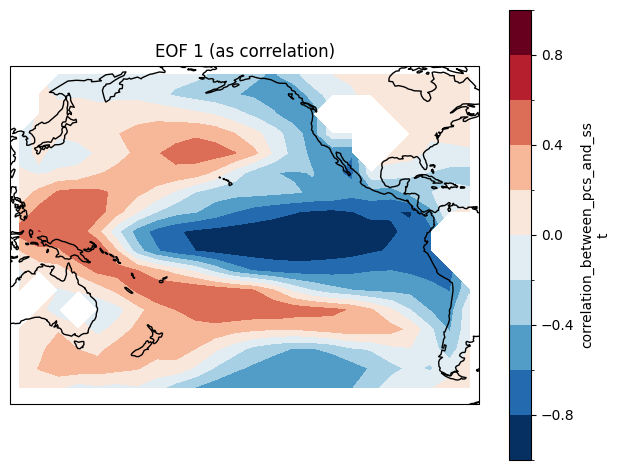

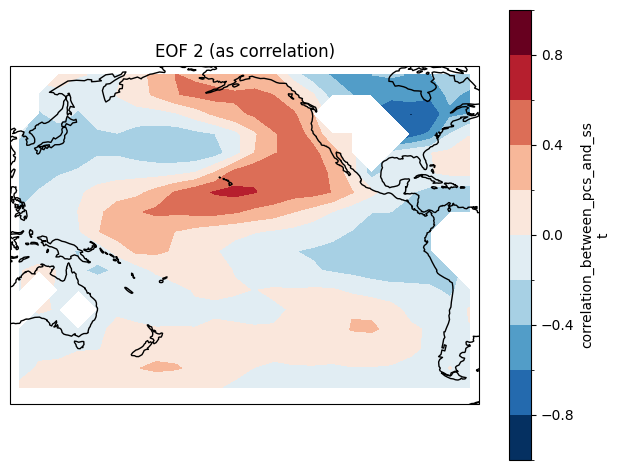

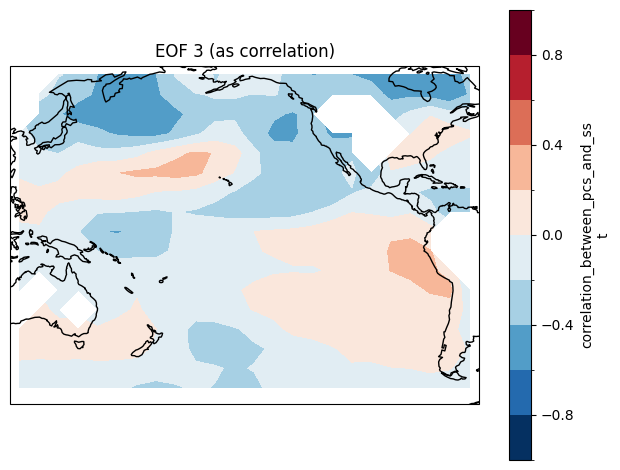

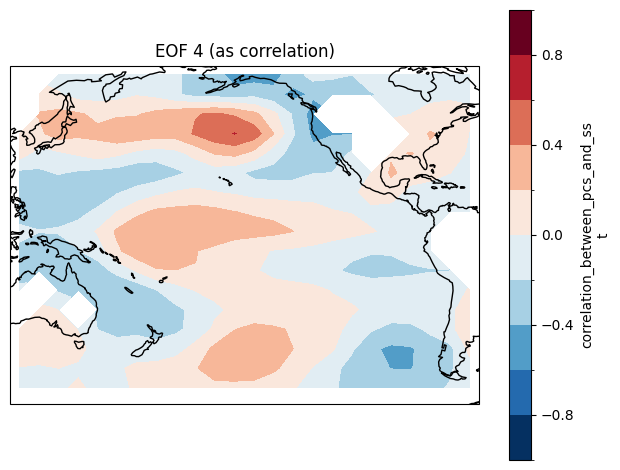

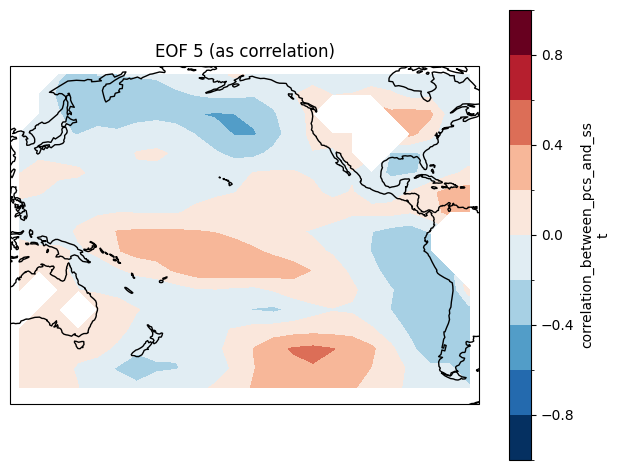

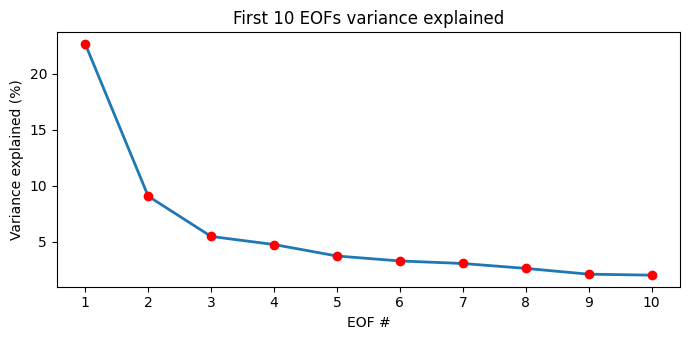

In [7]:
# -------- 5) maps of first 5 EOFs as correlation + variance fraction of first 10 --------
varfrac = solver.varianceFraction()
m_avail = int(varfrac.sizes["mode"])
maps_n = min(N_EOF_MAPS, m_avail)
eof_corr = solver.eofsAsCorrelation(neofs=maps_n)

clevs = np.linspace(-1, 1, 11)
for k in range(maps_n):
    if _HAS_CARTOPY:
        ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
        eof_corr.isel(mode=k).plot.contourf(
            ax=ax, levels=clevs, cmap=plt.cm.RdBu_r, add_colorbar=True, transform=ccrs.PlateCarree(), robust=True
        )
        ax.add_feature(cfeature.COASTLINE, edgecolor='k')
        ax.set_extent([120, 300, -65, 65], crs=ccrs.PlateCarree())
        plt.title(f'EOF {k+1} (as correlation)'); plt.tight_layout(); plt.show()
    else:
        eof_corr.isel(mode=k).plot(cmap="RdBu_r", robust=True)
        plt.title(f'EOF {k+1} (as correlation)'); plt.tight_layout(); plt.show()


plot_n = min(10, m_avail)
plt.figure(figsize=(7,3.5))
plt.plot(range(1, plot_n+1), (varfrac[:plot_n] * 100), linewidth=2)
plt.plot(range(1, plot_n+1), (varfrac[:plot_n] * 100),
         linestyle='None', marker='o', color='r', markersize=6)
plt.xticks(range(1, plot_n+1))
plt.xlabel('EOF #'); plt.ylabel('Variance explained (%)')
plt.title('First 10 EOFs variance explained'); plt.tight_layout(); plt.show()
pcs = solver.pcs(npcs=plot_n, pcscaling=1)  # for step 6 & 7

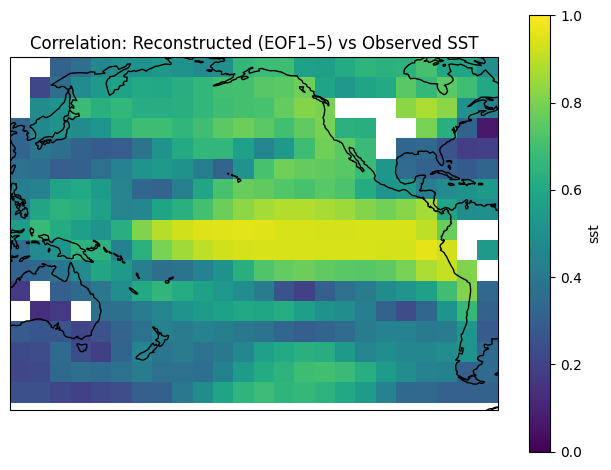

In [8]:
# -------- 6) reconstruct SST with first 5 EOFs and correlate with observed --------
K = min(RECON_K, m_avail)
recon = solver.reconstructedField(neofs=K)                     # (time, lat, lon)
corr_recon_obs = xr.corr(recon, sst_eof, dim="time")
quick_map(corr_recon_obs, title=f"Correlation: Reconstructed (EOF1–{K}) vs Observed SST",
          vmin=0, vmax=1, cmap="viridis", pacific_center=True)


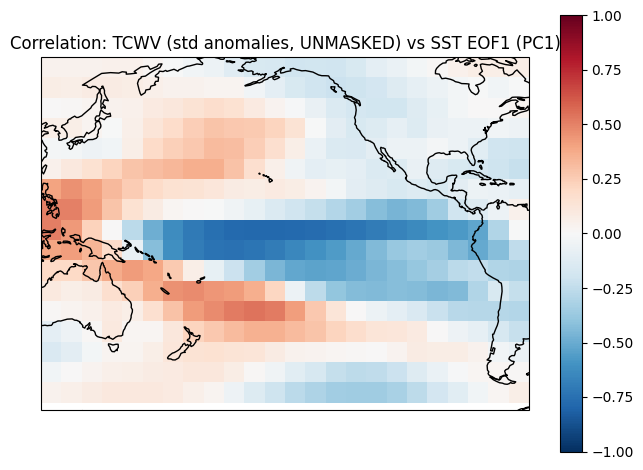

✅ Analysis done.


In [9]:
# -------- 7) correlate PC1 with UNMASKED TCWV anomalies (detrended, deseasonalized, standardized) --------
tcwv_full_pac_t = tcwv_full_pac.rename({time_dim: "time"}).astype("float32")
tcwv_on_grid = tcwv_full_pac_t.interp(
    latitude=sst_eof["latitude"], longitude=sst_eof["longitude"]
).astype("float32")

tcwv_detr = linear_detrend(tcwv_on_grid, time_dim="time").astype("float32")
tcwv_anom_full, _ = monthly_anom_and_z(tcwv_detr, time_dim="time", base_period=BASE_PERIOD)
tcwv_std = standardize_over_time(tcwv_anom_full, time_dim="time").astype("float32")

pc1 = pcs.isel(mode=0)
pc1_z = (pc1 - pc1.mean("time")) / pc1.std("time")
corr_tcwv_pc1 = xr.corr(tcwv_std, pc1_z, dim="time")
quick_map(corr_tcwv_pc1, title="Correlation: TCWV (std anomalies, UNMASKED) vs SST EOF1 (PC1)",
          vmin=-1, vmax=1, cmap="RdBu_r", pacific_center=True)

print("✅ Analysis done.")